# Task 4 — Channel effectiveness, measured
**CLO1.** Data: `channel_trials.csv` (30 trials: 5 channels × 6 ratios) and `iris.csv`.

A small-scale reproduction of Cleveland & McGill. Steps 1 and 5 are fully done here. Steps 2–4 need a real reader: the runner
is ready, and the analysis cells run once `channel_results.csv` exists. **No reader estimates are filled in by me.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# find the data folder whether the notebook sits in assignments/ or one level up
DATA = next(p for p in (Path("data"), Path("assignments/data"), Path("week2/assignments/data")) if p.exists())

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
})
GREY, RED, BLUE = "#bbbbbb", "#ee6677", "#4477aa"

trials = pd.read_csv(DATA / "channel_trials.csv")
iris = pd.read_csv(DATA / "iris.csv")
print(trials.shape); trials.head(8)

(30, 7)


,trial,channel,true_ratio,value_large,value_small,reader_estimate,absolute_error
0,1,position,0.15,76,11.40,NaN,NaN
1,2,position,0.25,59,14.75,NaN,NaN
2,3,position,0.40,76,30.40,NaN,NaN
3,4,position,0.55,68,37.40,NaN,NaN
4,5,position,0.70,61,42.70,NaN,NaN
5,6,position,0.85,64,54.40,NaN,NaN
6,7,length,0.15,70,10.50,NaN,NaN
7,8,length,0.25,86,21.50,NaN,NaN


## Step 1 — Encode each trial five ways
No axis labels, tick values or numbers anywhere: the reader judges from the channel alone.

| Channel | How the pair is drawn |
|---|---|
| position | two dots on a common 0–100 scale (a faint baseline marks zero) |
| length | two bars from a common zero baseline |
| angle | two wedges of one pie (wedge angle ∝ value) |
| area | two circles with **area** ∝ value (`s = K × value`, *not* value²) |
| colour | two squares, lightness ∝ value on a single-hue `Greys` ramp (no rainbow) |

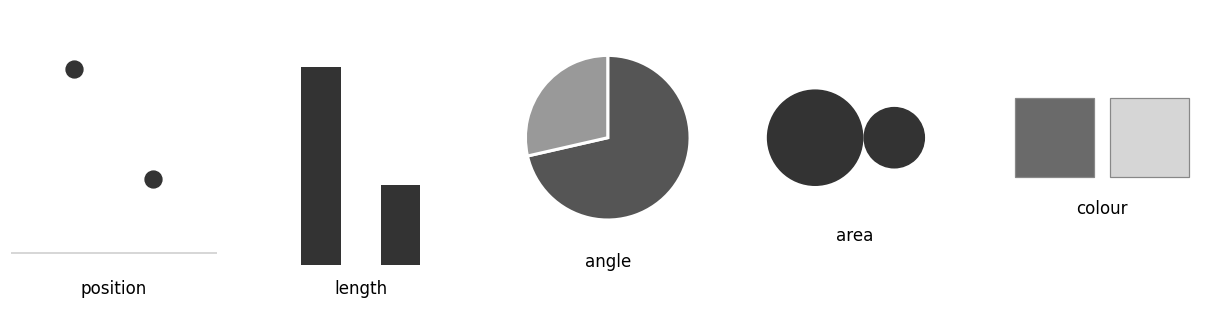

In [2]:
from matplotlib.patches import Rectangle

K_AREA = 45   # scatter s is AREA in points^2: s = K * value  -> area proportional to value (the correct way)

def draw_pair(ax, channel, large, small, large_first=True):
    a, b = (large, small) if large_first else (small, large)
    if channel == "position":
        ax.scatter([0, 1], [a, b], s=120, color="#333333", zorder=3)
        ax.axhline(0, color="#cccccc", lw=1); ax.set_xlim(-0.8, 1.8); ax.set_ylim(-5, 100)
    elif channel == "length":
        ax.bar([0, 1], [a, b], width=0.5, color="#333333")
        ax.set_xlim(-0.8, 1.8); ax.set_ylim(0, 100)
    elif channel == "angle":
        ax.pie([a, b], colors=["#555555", "#999999"], startangle=90, counterclock=False,
               wedgeprops=dict(edgecolor="white", linewidth=2))
    elif channel == "area":
        ax.scatter([0, 1], [0, 0], s=[K_AREA * a, K_AREA * b], color="#333333")
        ax.set_xlim(-0.8, 1.8); ax.set_ylim(-1, 1)
    elif channel == "colour":
        cmap = plt.cm.Greys
        for x, v in zip([0, 1.2], [a, b]):
            ax.add_patch(Rectangle((x, 0), 1, 1, facecolor=cmap(v / 100), edgecolor="#888888", lw=0.8))
        ax.set_xlim(-0.2, 2.4); ax.set_ylim(-0.2, 1.2)
    ax.axis("off")
    if channel != "angle":
        ax.set_aspect("auto" if channel in ("position", "length") else "equal")

CHANNELS = ["position", "length", "angle", "area", "colour"]
demo = trials[trials.true_ratio == 0.40]
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for ax, ch in zip(axes, CHANNELS):
    r = demo[demo.channel == ch].iloc[0]
    draw_pair(ax, ch, r.value_large, r.value_small)
    ax.text(0.5, -0.06, ch, transform=ax.transAxes, ha="center", va="top", fontsize=11)
fig.savefig("task4_five_channels_demo.png", dpi=200, bbox_inches="tight")
plt.show()

*Demo above: the same true ratio (0.40) in all five channels. I did not annotate which circle/square is the smaller one;
the reader's job is to judge it.* Area is encoded with `s = K × value` — area proportional to value. If I had set `s` proportional to
value² I would have built the classic area lie.

## Step 2 — Run all 30 trials on a real person
The runner shuffles the 30 trials, randomly flips which side holds the larger value (so side is not a cue), shows each chart,
and asks "the smaller one is what percentage of the larger?". It does **not** show the true answers.

Set `RUN_EXPERIMENT = True`, run the cell, and give the laptop to your reader. Do not answer for them.

In [3]:
from IPython.display import clear_output, display
READER = "a classmate"       # first name or "a classmate"
RUN_EXPERIMENT = False       # flip to True with a real person sitting there

def run_experiment(seed=None):
    rng = np.random.default_rng(seed)           # trial order only - the stimuli themselves are untouched
    order = rng.permutation(len(trials))
    out = trials.copy()
    for step, idx in enumerate(order, start=1):
        r = trials.iloc[idx]
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(4, 3.2))
        draw_pair(ax, r.channel, r.value_large, r.value_small, large_first=bool(rng.integers(2)))
        display(fig); plt.close(fig)
        while True:
            try:
                est = float(input(f"[{step}/30] The smaller one is what % of the larger? "))
                if 0 <= est <= 150: break
            except ValueError:
                pass
        out.loc[trials.index[idx], "reader_estimate"] = est
    out["absolute_error"] = (out.reader_estimate / 100 - out.true_ratio).abs()
    out.to_csv("channel_results.csv", index=False)
    clear_output(wait=True); print("Saved channel_results.csv")
    return out

if RUN_EXPERIMENT:
    results = run_experiment()

## Step 3 and 4 — Error, then rank the channels
`absolute_error = abs(reader_estimate/100 - true_ratio)`, saved to `channel_results.csv`. The ranking plot has one bar per
channel, sorted, zero baseline, with the standard error across its six trials.

In [4]:
RES = Path("channel_results.csv")
EXPECTED = ["position", "length", "angle", "area", "colour"]   # published order (volume has no trial here)

if RES.exists():
    res = pd.read_csv(RES)
    res["absolute_error"] = (res.reader_estimate / 100 - res.true_ratio).abs()
    res.to_csv("channel_results.csv", index=False)
    stats = res.groupby("channel").absolute_error.agg(mean="mean", sem=lambda s: s.std(ddof=1) / np.sqrt(len(s)), n="size")
    stats = stats.sort_values("mean")
    best = stats.index[0]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.bar(stats.index, stats["mean"], yerr=stats["sem"], capsize=4,
           color=[RED if c == stats.index[-1] else GREY for c in stats.index])
    for i, v in enumerate(stats["mean"]):
        ax.text(i, v + 0.012, f"{v:.2f}", ha="center")
    ax.set_ylim(0, None)
    ax.set_ylabel("Mean absolute error (ratio, 0 = perfect)")
    ax.set_title("FINDING GOES HERE: write it after you see your own ranking", loc="left")
    fig.text(0.01, -0.02, f"One reader ({READER}); n = {len(res)} trials (6 per channel); error bars = standard error.",
             fontsize=8, color="#555555")
    fig.savefig("task4_channel_ranking.png", dpi=300, bbox_inches="tight")
    plt.show()
    display(stats.round(3))
    print("My ranking (best -> worst):    ", " > ".join(stats.index))
    print("Published ranking (best -> worst):", " > ".join(EXPECTED))
else:
    print("channel_results.csv not found - run Step 2 with a real reader first.")

channel_results.csv not found - run Step 2 with a real reader first.


> ✏️ **After you have results:** replace the title placeholder with your actual finding (the most and least accurate channel for
> *your* reader). The worst bar carries the one strong colour (the single pop-out).
> Then write where your ranking agrees with `position > length > angle > area > volume > colour` and where it does not. Remember there is
> no `volume` trial here, so only five channels are compared. A disagreement is fine **if you say so and give a reason**: one
> reader, six ratios per channel, and your reader may use strategies a pure channel test does not intend (e.g. mentally
> comparing a bar length against the edge of the screen).

## Step 5 — Apply it with `iris.csv`
Same finding, two channels. **Finding:** petal length separates the three species, and *virginica* petals are about four times
as long as *setosa* petals.
* **Left:** `petal_length` on **position** (high-ranking). Individual flowers in grey for context, species mean in the one strong
  colour (virginica); the dot's height on the common axis carries the value.
* **Right:** the same species means on **area** (low-ranking). Circle area ∝ mean petal length; two reference circles give the scale.

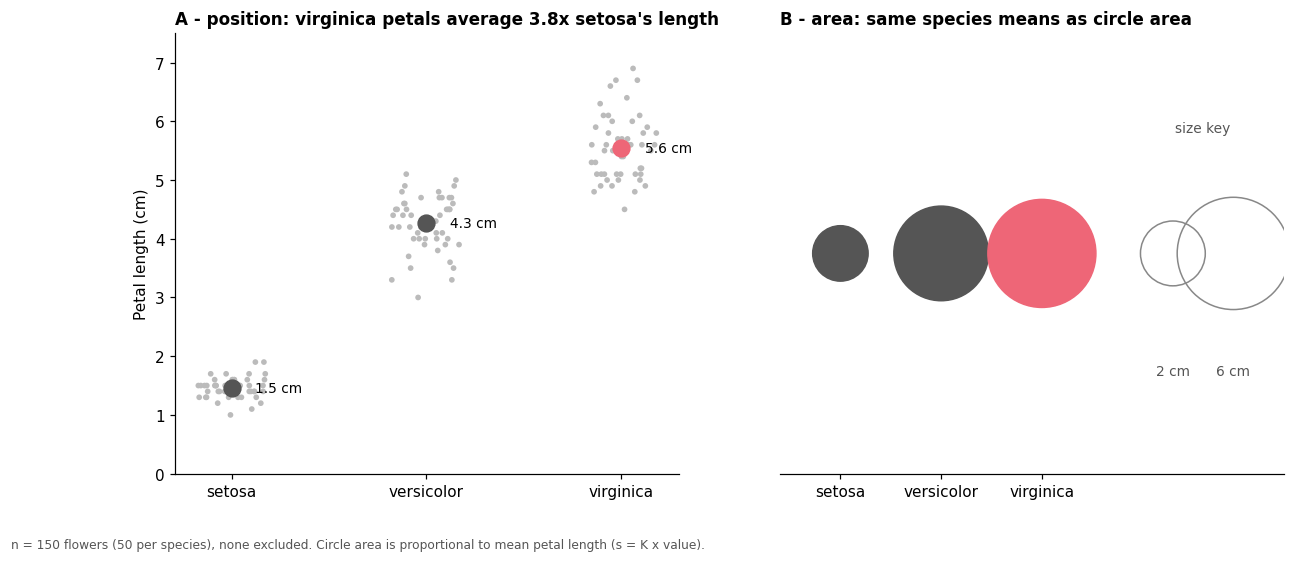

True ratio setosa/virginica = 0.26
If the reader's apparent-area exponent is ~0.7 (Stevens' power law for area), they would perceive about 0.39


In [5]:
means = iris.groupby("species").petal_length.mean()
order = list(means.index)       # setosa, versicolor, virginica
ratio = means["virginica"] / means["setosa"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# --- A: position on a common scale
ax = axes[0]
rng = np.random.default_rng(1)       # jitter only; cosmetic
for i, sp in enumerate(order):
    d = iris[iris.species == sp]
    ax.scatter(i + rng.uniform(-0.18, 0.18, len(d)), d.petal_length, s=14, color=GREY, edgecolors="none")
    ax.scatter(i, means[sp], s=120, color=RED if sp == "virginica" else "#555555", zorder=3)
    ax.text(i + 0.12, means[sp], f"{means[sp]:.1f} cm", va="center", fontsize=9)
ax.set_xticks(range(3)); ax.set_xticklabels(order)
ax.set_ylim(0, 7.5); ax.set_ylabel("Petal length (cm)")
ax.set_title(f"A - position: virginica petals average {ratio:.1f}x setosa's length", loc="left")

# --- B: area (s is AREA, so s = K * value)
ax = axes[1]
K = 900
ax.scatter(range(3), [0] * 3, s=K * means.values, color=["#555555", "#555555", RED], zorder=3)
ax.scatter([3.3, 3.9], [0, 0], s=[K * 2, K * 6], facecolor="none", edgecolor="#888888", zorder=2)
ax.text(3.3, -0.55, "2 cm", ha="center", fontsize=9, color="#555555")
ax.text(3.9, -0.55, "6 cm", ha="center", fontsize=9, color="#555555")
ax.text(3.6, 0.55, "size key", ha="center", fontsize=9, color="#555555")
ax.set_xticks(range(3)); ax.set_xticklabels(order)
ax.set_xlim(-0.6, 4.4); ax.set_ylim(-1, 1); ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.set_title("B - area: same species means as circle area", loc="left")

fig.text(0.01, -0.02, "n = 150 flowers (50 per species), none excluded. Circle area is proportional to mean petal length (s = K x value).",
         fontsize=8, color="#555555")
fig.savefig("task4_iris_two_channels.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"True ratio setosa/virginica = {means['setosa']/means['virginica']:.2f}")
print(f"If the reader's apparent-area exponent is ~0.7 (Stevens' power law for area), they would perceive about "
      f"{(means['setosa']/means['virginica'])**0.7:.2f}")

**Which I would publish: A (position).** Reason, in terms of decoding accuracy: on a common scale the reader compares
distances against an axis, one of the most accurate judgements people make, and the gap between setosa and virginica is read
directly. In B the reader has to judge areas; people systematically under-judge area differences (perceived area grows more slowly
than true area, with an exponent around 0.7), so the same data look *less* different than they are, and the exact ratio cannot
be read without the key. The point is not that B looks worse, it is that readers decode A more accurately. B is only
defensible if the exact value is printed on the circle.

## The question to answer: what can this experiment support?
**Cannot support:** any claim about people in general. It has **one** reader and 30 trials, 6 per channel, so the standard
errors are large relative to the differences between neighbouring channels (angle vs area, say). There is no randomisation of
readers, no repeats of each ratio, no volume condition, and learning effects and fatigue are not controlled. A swapped rank
between two close channels in my table is well within what noise could produce.

**Can support:** a rough sanity check. If the best channel for my reader is position/length and the worst is colour or area, that is
consistent with the published ranking, and the method (blind estimates against known truth, error as the outcome) is the
right one.

**Why follow the published ranking anyway:** Cleveland & McGill's result (and later replications such as Heer & Bostock's
crowdsourced versions) rests on many participants and many trials, so it has the statistical power mine does not. Its
mechanism is also consistent with how perception works: position and length can be judged against a common reference,
whereas angle, area and lightness cannot. When my small sample disagrees with a large, repeated finding, the likelier
explanation is noise in my sample, not that the ranking is wrong.